بسم الله

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
import xgboost as xgb
from tabulate import tabulate

# إعدادات العرض
sns.set(style='whitegrid', palette='muted', color_codes=True)

# النمذجة التنبؤية
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, auc
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

# تثبيت العشوائية
import random
random.seed(42)
np.random.seed(42)

# مكتبة الإحصاء والتحذيرات
import scipy.stats as stats
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Load the first air quality dataset
file_path_1 = '/kaggle/input/air-quality-dataset/air_quality_dataset.csv'
df = pd.read_csv(file_path_1, encoding='ascii', delimiter=',')

# Display basic information
print('First few rows of the Air Quality Dataset:')
display(df.head())

print('\nDataset Info:')
df.info()

print('\nDescriptive Statistics:')
display(df.describe())

First few rows of the Air Quality Dataset:


,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature,Humidity,Wind_Direction,Location_Type,Source_Label
0,39.967142,57.926035,116.192213,55.230299,4.531693,75.317261,2.789606,427.674347,1.706105,31.085120,45.454749,276,Urban,Vehicular
1,101.935672,150.774299,76.826826,79.051618,18.744780,145.083987,1.966569,529.739619,2.492663,33.711103,60.798212,134,Industrial,Industrial
2,70.996192,138.948796,158.731020,60.466604,14.892239,145.147338,2.626446,499.889443,2.431165,33.778698,54.875669,1,Industrial,Industrial
3,28.464728,63.643900,25.385343,15.333286,7.647429,130.022319,1.779360,388.283712,1.818563,31.565877,67.113319,251,Rural,Biomass Burning
4,78.265276,113.977926,105.644340,59.202337,17.696806,181.713667,3.240533,464.739197,2.597225,32.229835,37.236519,326,Industrial,Industrial



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   PM2.5           500 non-null    float64
 1   PM10            500 non-null    float64
 2   NOx             500 non-null    float64
 3   NO2             500 non-null    float64
 4   SO2             500 non-null    float64
 5   VOCs            500 non-null    float64
 6   CO              500 non-null    float64
 7   CO2             500 non-null    float64
 8   CH4             500 non-null    float64
 9   Temperature     500 non-null    float64
 10  Humidity        500 non-null    float64
 11  Wind_Direction  500 non-null    int64  
 12  Location_Type   500 non-null    object 
 13  Source_Label    500 non-null    object 
dtypes: float64(11), int64(1), object(2)
memory usage: 54.8+ KB

Descriptive Statistics:


,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature,Humidity,Wind_Direction
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,54.671620,84.703251,91.814080,42.410820,11.504816,112.193098,2.177705,439.288087,2.130439,30.448413,56.196914,180.842000
std,22.799473,30.567912,54.808414,26.343669,7.306978,39.471686,0.824762,51.220578,0.391396,2.957290,11.035563,102.323767
min,10.757597,12.932337,-0.076323,-1.942140,-1.095555,27.555617,0.366992,366.063158,1.388407,19.581349,35.077851,0.000000
25%,36.372940,61.118607,35.457263,17.448632,5.976492,81.516729,1.536915,397.399610,1.837395,28.481974,47.254489,95.750000
50%,48.038599,78.135558,95.452284,39.211583,8.681222,104.819124,2.045519,420.934319,2.066709,30.432756,55.816773,183.000000
75%,73.820566,110.270086,134.709240,63.817763,17.116673,140.588100,2.726020,490.968315,2.386267,32.614954,64.022677,267.000000
max,127.616632,171.594187,225.886935,115.916428,31.941860,231.926017,4.798935,558.924257,3.352266,39.778713,79.991414,359.000000


In [3]:
df.shape


(500, 14)

In [4]:
df.tail()


,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature,Humidity,Wind_Direction,Location_Type,Source_Label
495,51.380025,57.573550,31.124630,19.276010,11.167098,104.071502,1.844483,397.418878,1.923525,34.323410,67.148831,289,Rural,Biomass Burning
496,46.816837,75.372133,22.174014,18.535162,12.169426,74.802208,1.364096,392.316075,2.157281,26.321361,65.549718,270,Rural,Biomass Burning
497,33.909351,88.097250,27.630317,15.653370,7.997326,128.105470,2.319453,378.653347,1.809489,28.964494,72.687008,185,Rural,Biomass Burning
498,43.721651,40.847991,27.253977,19.365916,7.218154,106.053329,1.599748,389.878566,1.858964,29.976442,65.043244,272,Rural,Biomass Burning
499,43.135587,34.287210,4.290139,5.122962,7.415822,93.332250,1.633200,388.029985,2.059903,26.649351,72.726452,239,Rural,Biomass Burning


In [5]:
df.shape


(500, 14)

In [6]:
df.isna().sum()


PM2.5             0
PM10              0
NOx               0
NO2               0
SO2               0
VOCs              0
CO                0
CO2               0
CH4               0
Temperature       0
Humidity          0
Wind_Direction    0
Location_Type     0
Source_Label      0
dtype: int64

<Axes: >

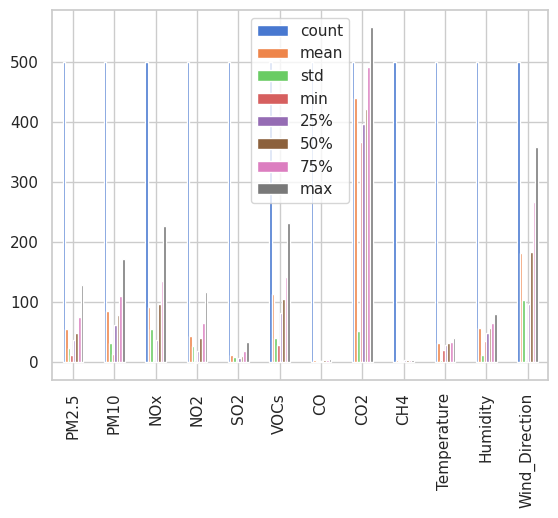

In [7]:
df.describe().T.plot(kind='bar')


In [8]:
df.columns.to_list()


['PM2.5',
 'PM10',
 'NOx',
 'NO2',
 'SO2',
 'VOCs',
 'CO',
 'CO2',
 'CH4',
 'Temperature',
 'Humidity',
 'Wind_Direction',
 'Location_Type',
 'Source_Label']

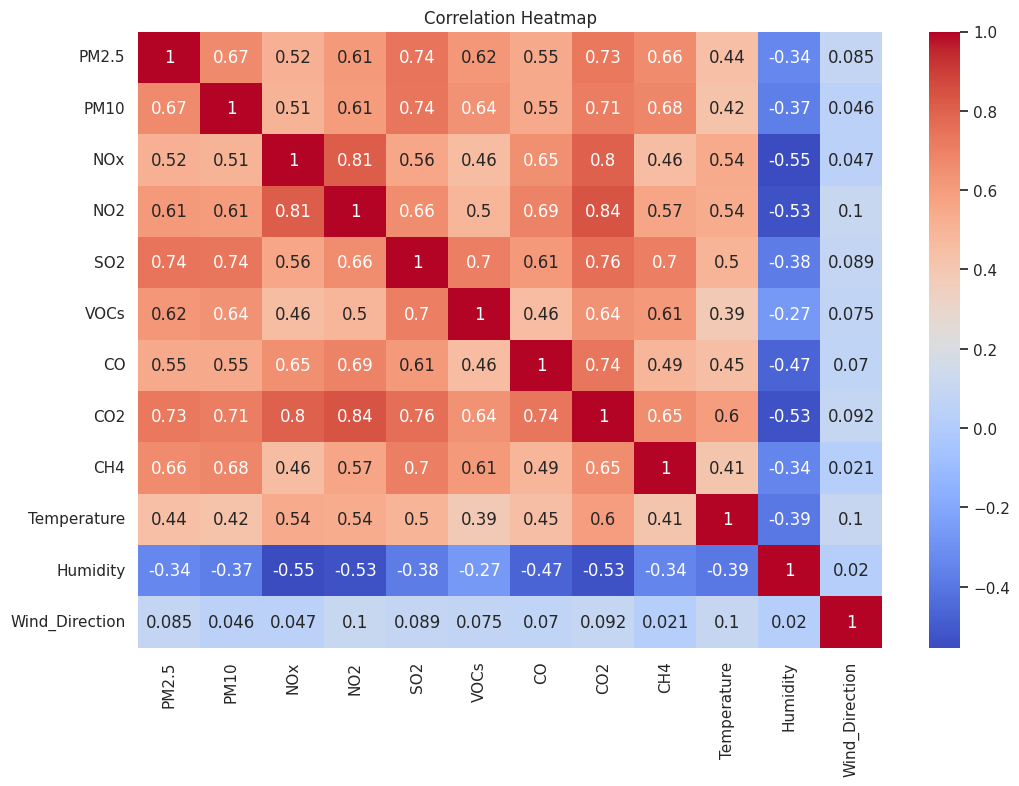

In [9]:
# Correlation heatmap
numeric_df = df.select_dtypes(include=[np.number])
plt.figure(figsize=(12, 8))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [10]:
df.duplicated().sum()


0

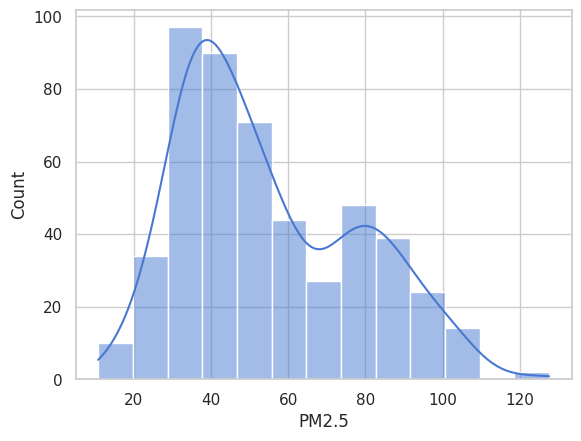

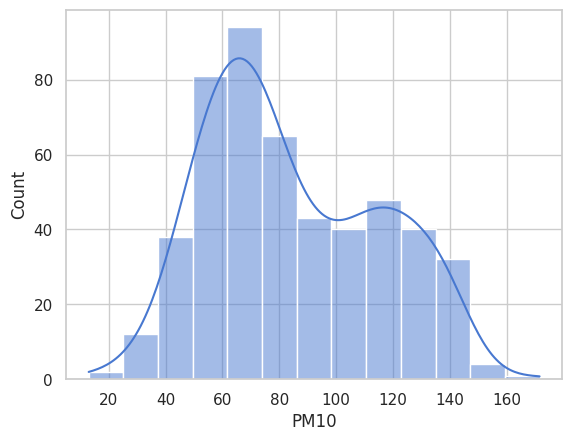

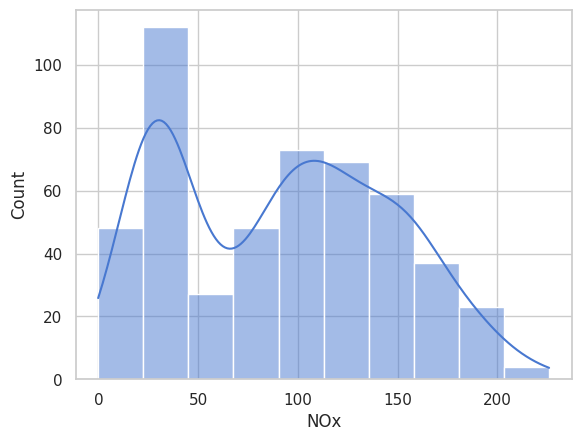

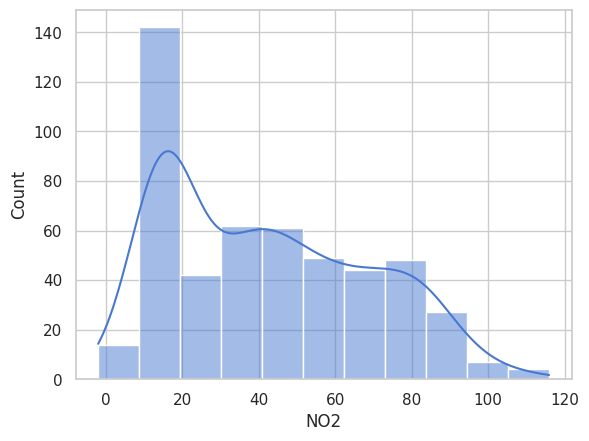

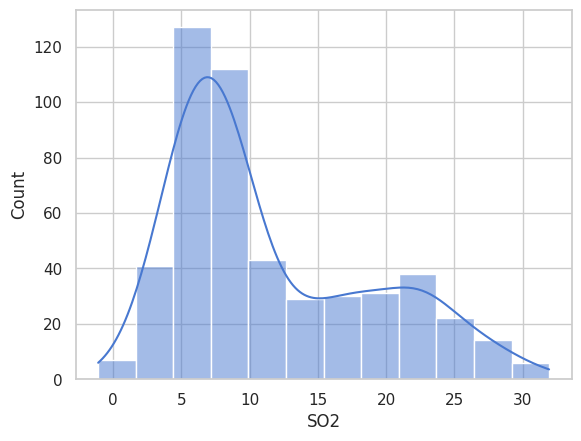

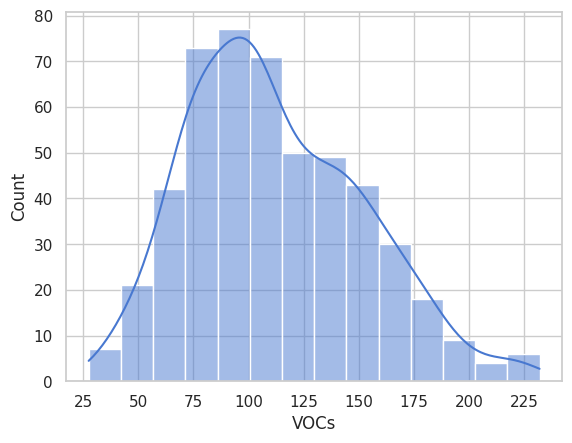

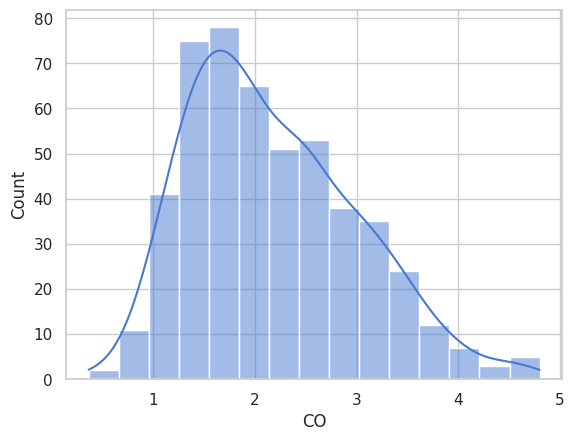

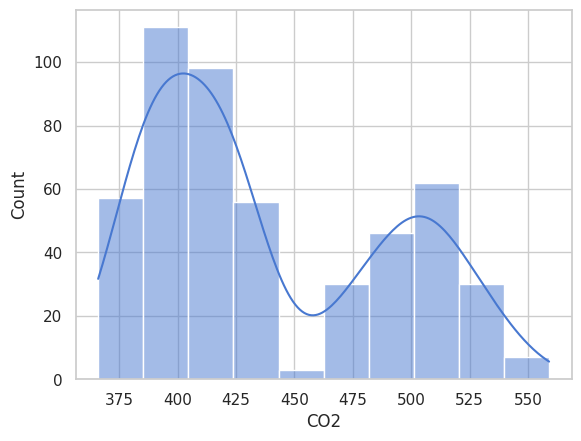

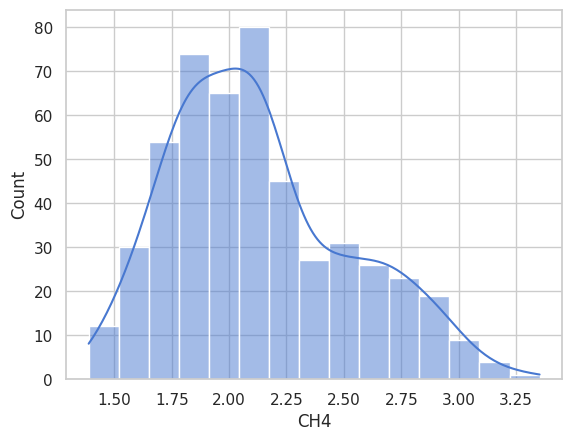

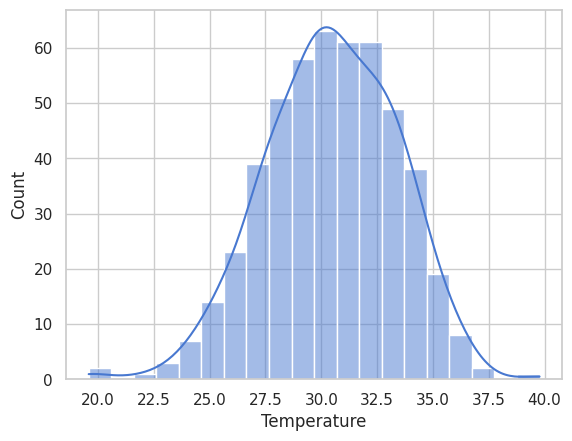

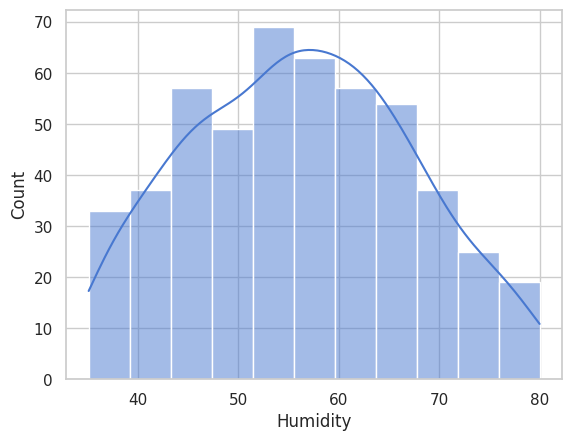

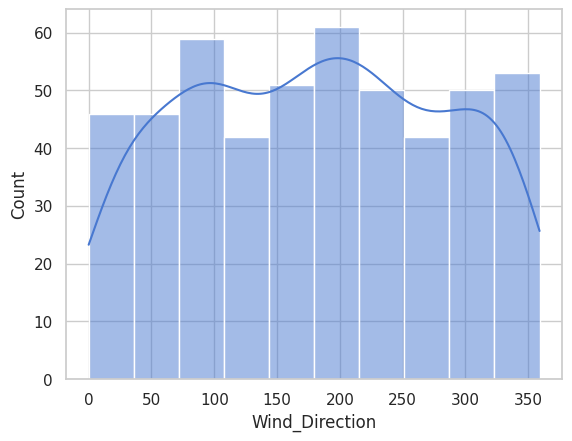

In [11]:
numeric_cols = df.select_dtypes(include=['number']).columns

# رسم التوزيع لكل عمود رقمي
for col in numeric_cols:
    sns.histplot(x=col, data=df, kde=True)
    plt.show()